In [ ]:
########### KUMARS IMAGINED DATASET

In [1]:
pip install mne

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


Extracting EDF parameters from C:\Users\HP\Desktop\Imagined_speech_EEG_edf\Digit\name0_0.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 1535  =      0.000 ...    11.992 secs...
<Info | 8 non-empty values
 bads: []
 ch_names: COUNTER, INTERPOLATED, AF3, F7, F3, FC5, T7, P7, O1, O2, P8, T8, ...
 chs: 39 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 64.0 Hz
 meas_date: 2017-02-25 19:37:51 UTC
 nchan: 39
 projs: []
 sfreq: 128.0 Hz
 subject_info: <subject_info | his_id: 1>
>
Using matplotlib as 2D backend.


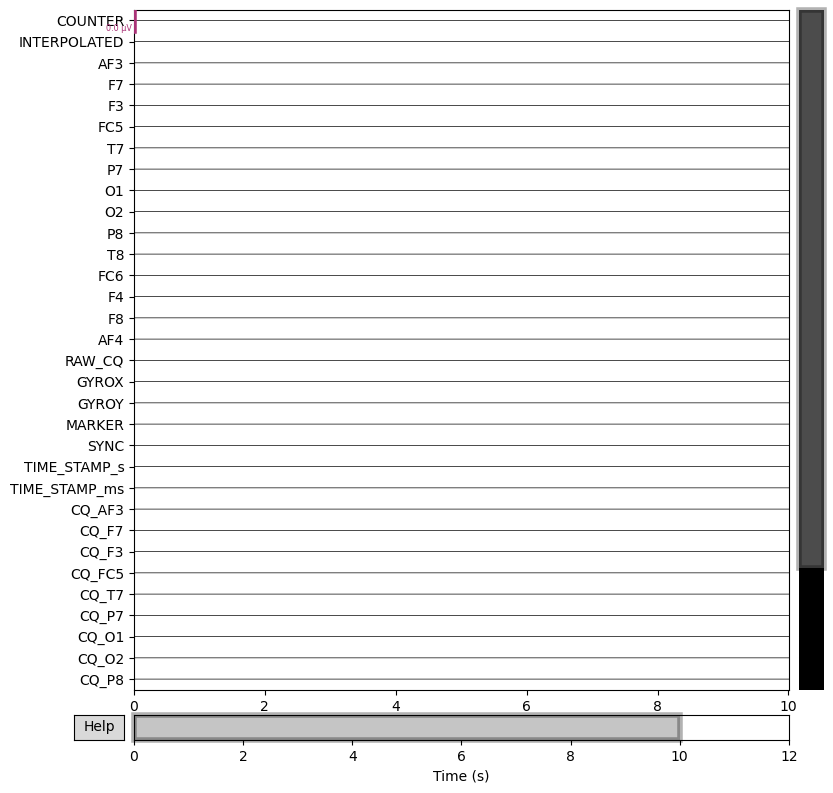

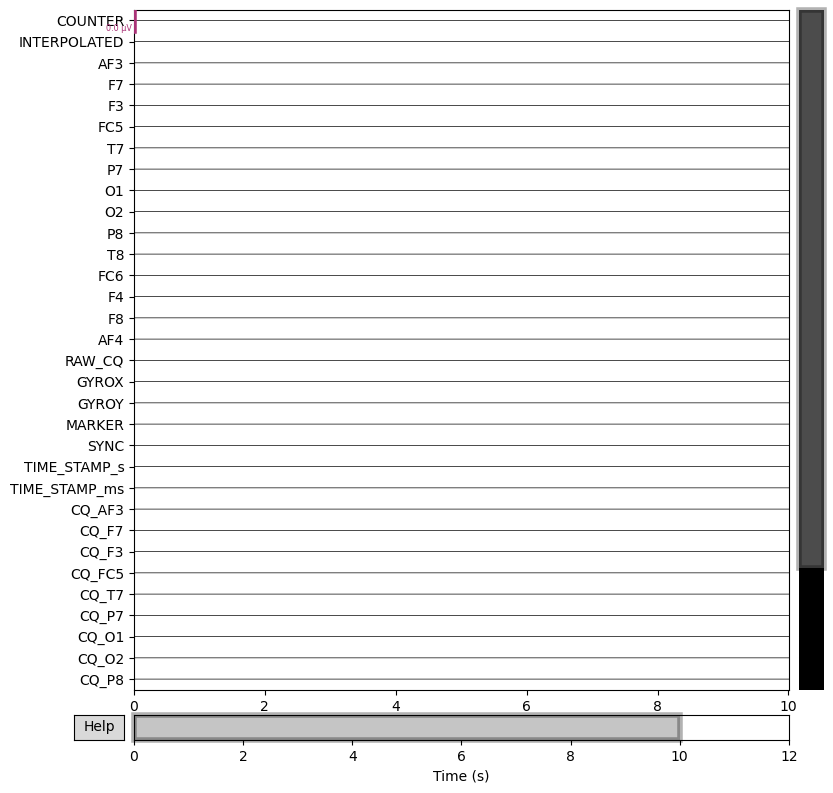

In [6]:
edf_path="C:/Users/HP/Desktop/Imagined_speech_EEG_edf/Digit/name0_0.edf"
import mne

# Load the raw EEG data
raw = mne.io.read_raw_edf(edf_path, preload=True)

# Print basic info
print(raw.info)

# Plot EEG signals (optional, for visualization)
raw.plot(n_channels=32, scalings='auto')

In [8]:
import numpy as np
import pandas as pd

# Get data as a NumPy array (shape: [n_channels, n_samples])
data, times = raw.get_data(return_times=True)

# Convert to DataFrame
df = pd.DataFrame(data.T, columns=raw.ch_names)
df["Time (s)"] = times  # Add time column

# Display first few rows
print(df.head())

    COUNTER  INTERPOLATED       AF3        F7        F3       FC5        T7  \
0  0.000048           0.0  0.004209  0.004253  0.004243  0.004246  0.004227   
1  0.000049           0.0  0.004221  0.004259  0.004260  0.004260  0.004231   
2  0.000050           0.0  0.004218  0.004252  0.004256  0.004254  0.004231   
3  0.000051           0.0  0.004204  0.004249  0.004241  0.004245  0.004228   
4  0.000052           0.0  0.004216  0.004256  0.004260  0.004258  0.004228   

         P7        O1        O2  ...  CQ_O2  CQ_P8  CQ_T8  CQ_FC6  CQ_F4  \
0  0.004239  0.004227  0.004220  ...    0.0    0.0    0.0     0.0    0.0   
1  0.004242  0.004234  0.004223  ...    0.0    0.0    0.0     0.0    0.0   
2  0.004239  0.004233  0.004217  ...    0.0    0.0    0.0     0.0    0.0   
3  0.004237  0.004229  0.004204  ...    0.0    0.0    0.0     0.0    0.0   
4  0.004241  0.004241  0.004203  ...    0.0    0.0    0.0     0.0    0.0   

   CQ_F8  CQ_AF4  CQ_CMS  CQ_DRL  Time (s)  
0    0.0     0.0     0.

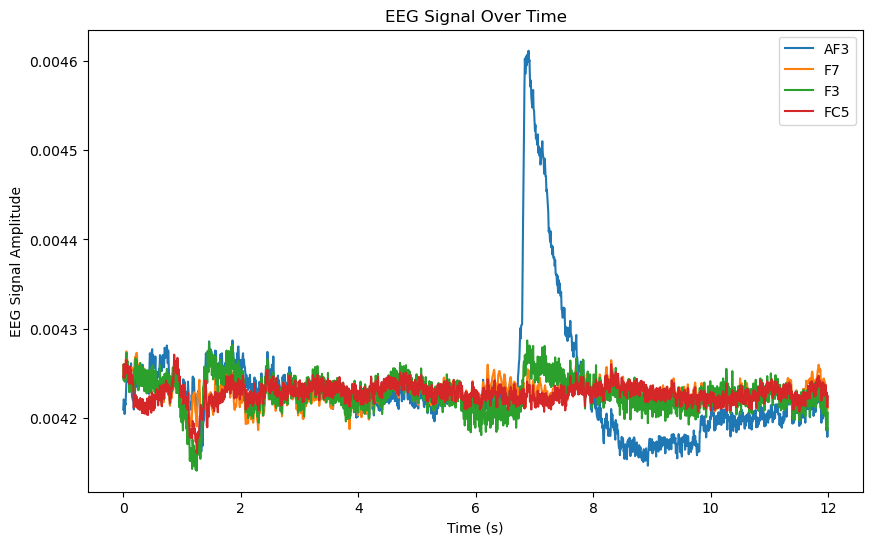

In [10]:
import matplotlib.pyplot as plt
channels_to_plot = ["AF3", "F7", "F3", "FC5"]

plt.figure(figsize=(10, 6))
for ch in channels_to_plot:
    plt.plot(times, df[ch], label=ch)

plt.xlabel("Time (s)")
plt.ylabel("EEG Signal Amplitude")
plt.title("EEG Signal Over Time")
plt.legend()
plt.show()


In [14]:
import mne
import os
import glob
import numpy as np
import pandas as pd

# Set MNE to suppress verbose output
mne.set_log_level('ERROR')

# Define paths
main_folder = r"C:\Users\HP\Desktop\Imagined_speech_EEG_edf"
output_folder = r"C:\Users\HP\Desktop\Imagined_speech_EEG_csv"

# Create output folder if it doesn't exist
os.makedirs(output_folder, exist_ok=True)

# Subfolders to process
subfolders = ["Digit", "Char", "Image"]

# Function to read and clean EEG data
def process_edf_to_csv(file_path, output_folder):
    # Read EDF file
    raw = mne.io.read_raw_edf(file_path, preload=True)
    
    # Get data and channel names
    data, times = raw[:]
    channels = raw.ch_names
    
    # Create DataFrame
    df = pd.DataFrame(data.T, columns=channels)
    df['time'] = times
    
    # Check for null values and drop
    if df.isnull().any().any():
        print(f"Found null values in {file_path}, dropping...")
        df = df.dropna()
    
    # Generate output filename (same as EDF, e.g., name0_A.csv)
    base_name = os.path.basename(file_path).replace('.edf', '.csv')
    output_path = os.path.join(output_folder, base_name)
    
    # Save to CSV
    df.to_csv(output_path, index=False)
    print(f"Saved {output_path} with shape {df.shape}")

# Process all EDF files
for subfolder in subfolders:
    folder_path = os.path.join(main_folder, subfolder)
    edf_files = glob.glob(os.path.join(folder_path, "*.edf"))
    
    for file in edf_files:
        process_edf_to_csv(file, output_folder)

print("Processing complete. CSV files saved in", output_folder)

Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_0.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_1.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_2.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_3.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_4.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_5.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_6.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_7.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_8.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name0_9.csv with shape (1536, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name10_0.csv with shape (1664, 40)
Saved C:\Users\HP\Desktop\Imagined_speech_EEG_csv\name10_1.csv with shape (

In [20]:
path=""
import pandas as pd
df=pd.read_csv(path)
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1536 entries, 0 to 1535
Data columns (total 40 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   COUNTER        1536 non-null   float64
 1   INTERPOLATED   1536 non-null   float64
 2   AF3            1536 non-null   float64
 3   F7             1536 non-null   float64
 4   F3             1536 non-null   float64
 5   FC5            1536 non-null   float64
 6   T7             1536 non-null   float64
 7   P7             1536 non-null   float64
 8   O1             1536 non-null   float64
 9   O2             1536 non-null   float64
 10  P8             1536 non-null   float64
 11  T8             1536 non-null   float64
 12  FC6            1536 non-null   float64
 13  F4             1536 non-null   float64
 14  F8             1536 non-null   float64
 15  AF4            1536 non-null   float64
 16  RAW_CQ         1536 non-null   float64
 17  GYROX          1536 non-null   float64
 18  GYROY   

In [26]:
import os
import pandas as pd

# Folder containing full-channel EEG CSVs
input_folder = "C:/Users/HP/Desktop/Imagined_speech_EEG_csv"

# Optional: Set a different output folder if you don't want to overwrite
# output_folder = "/content/drive/MyDrive/Colab Notebooks/Cleaned_EEG_CSVs"
# os.makedirs(output_folder, exist_ok=True)

# EEG channels to keep
EEG_CHANNELS = ["F7", "F8", "F3", "F4", "AF3", "AF4",
                "FC5", "FC6", "T7", "T8", "P7", "P8", "O1", "O2"]

# Go through each CSV file and keep only the needed columns
for filename in os.listdir(input_folder):
    if filename.endswith(".csv"):
        file_path = os.path.join(input_folder, filename)
        
        try:
            df = pd.read_csv(file_path)
            
            # Keep only the EEG_CHANNELS that exist in the file
            df_filtered = df[[col for col in EEG_CHANNELS if col in df.columns]]

            # Option 1: Overwrite the original file
            df_filtered.to_csv(file_path, index=False)

            # Option 2: Save to a new folder
            # df_filtered.to_csv(os.path.join(output_folder, filename), index=False)

            print(f"✅ Processed: {filename}")

        except Exception as e:
            print(f"❌ Error processing {filename}: {e}")

print("🎉 All files cleaned and saved!")


✅ Processed: name0_0.csv
✅ Processed: name0_1.csv
✅ Processed: name0_2.csv
✅ Processed: name0_3.csv
✅ Processed: name0_4.csv
✅ Processed: name0_5.csv
✅ Processed: name0_6.csv
✅ Processed: name0_7.csv
✅ Processed: name0_8.csv
✅ Processed: name0_9.csv
✅ Processed: name0_A.csv
✅ Processed: name0_Apple.csv
✅ Processed: name0_C.csv
✅ Processed: name0_Car.csv
✅ Processed: name0_Dog.csv
✅ Processed: name0_F.csv
✅ Processed: name0_Gold.csv
✅ Processed: name0_H.csv
✅ Processed: name0_J.csv
✅ Processed: name0_M.csv
✅ Processed: name0_Mobile.csv
✅ Processed: name0_P.csv
✅ Processed: name0_Rose.csv
✅ Processed: name0_S.csv
✅ Processed: name0_Scooter.csv
✅ Processed: name0_T.csv
✅ Processed: name0_Tiger.csv
✅ Processed: name0_Wallet.csv
✅ Processed: name0_Watch.csv
✅ Processed: name0_Y.csv
✅ Processed: name10_0.csv
✅ Processed: name10_1.csv
✅ Processed: name10_2.csv
✅ Processed: name10_3.csv
✅ Processed: name10_4.csv
✅ Processed: name10_5.csv
✅ Processed: name10_6.csv
✅ Processed: name10_7.csv
✅ Pr

In [28]:
import os
import pandas as pd
import numpy as np
from scipy.signal import butter, filtfilt

# Define EEG channels
EEG_CHANNELS = ["F7", "F8", "F3", "F4", "AF3", "AF4",
                "FC5", "FC6", "T7", "T8", "P7", "P8", "O1", "O2"]

# Bandpass filter: 0.5–50 Hz
def bandpass_filter(data, lowcut=0.5, highcut=50, fs=256, order=4):
    nyquist = 0.5 * fs
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(order, [low, high], btype='band')
    return filtfilt(b, a, data)

# IQR-based outlier removal
def remove_outliers_iqr(df):
    Q1 = df.quantile(0.25)
    Q3 = df.quantile(0.75)
    IQR = Q3 - Q1
    return df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]

# Process a single file
def preprocess_eeg_file(file_path):
    df = pd.read_csv(file_path)
    
    # Keep only EEG channels
    df = df[EEG_CHANNELS]

    # Apply bandpass filter channel-wise
    for col in EEG_CHANNELS:
        df[col] = bandpass_filter(df[col])

    # Remove outliers using IQR
    df = remove_outliers_iqr(df)

    return df

# Process all EEG CSV files in a folder
def preprocess_all_files(input_dir, output_dir):
    os.makedirs(output_dir, exist_ok=True)

    files = [f for f in os.listdir(input_dir) if f.endswith(".csv")]

    for i, file in enumerate(files, start=1):
        file_path = os.path.join(input_dir, file)
        output_path = os.path.join(output_dir, file)
        
        try:
            processed_df = preprocess_eeg_file(file_path)
            processed_df.to_csv(output_path, index=False)
            print(f"✅ {i}/{len(files)} Processed: {file}")
        except Exception as e:
            print(f"❌ Error processing {file}: {e}")

# Set your paths
input_directory = "C:/Users/HP/Desktop/Imagined_speech_EEG_csv"
output_directory = "C:/Users/HP/Desktop/Preprocessed_EEG_CSV"

# Run preprocessing
preprocess_all_files(input_directory, output_directory)


✅ 1/690 Processed: name0_0.csv
✅ 2/690 Processed: name0_1.csv
✅ 3/690 Processed: name0_2.csv
✅ 4/690 Processed: name0_3.csv
✅ 5/690 Processed: name0_4.csv
✅ 6/690 Processed: name0_5.csv
✅ 7/690 Processed: name0_6.csv
✅ 8/690 Processed: name0_7.csv
✅ 9/690 Processed: name0_8.csv
✅ 10/690 Processed: name0_9.csv
✅ 11/690 Processed: name0_A.csv
✅ 12/690 Processed: name0_Apple.csv
✅ 13/690 Processed: name0_C.csv
✅ 14/690 Processed: name0_Car.csv
✅ 15/690 Processed: name0_Dog.csv
✅ 16/690 Processed: name0_F.csv
✅ 17/690 Processed: name0_Gold.csv
✅ 18/690 Processed: name0_H.csv
✅ 19/690 Processed: name0_J.csv
✅ 20/690 Processed: name0_M.csv
✅ 21/690 Processed: name0_Mobile.csv
✅ 22/690 Processed: name0_P.csv
✅ 23/690 Processed: name0_Rose.csv
✅ 24/690 Processed: name0_S.csv
✅ 25/690 Processed: name0_Scooter.csv
✅ 26/690 Processed: name0_T.csv
✅ 27/690 Processed: name0_Tiger.csv
✅ 28/690 Processed: name0_Wallet.csv
✅ 29/690 Processed: name0_Watch.csv
✅ 30/690 Processed: name0_Y.csv
✅ 31/690 Pr

In [32]:
from sklearn.preprocessing import LabelEncoder
import os

# Path to preprocessed EEG files
data_dir = "C:/Users/HP/Desktop/Preprocessed_EEG_CSV"

# Extract labels from filenames like: name10_a_1.csv
file_list = [f for f in os.listdir(data_dir) if f.endswith(".csv")]
labels = [filename.split("_")[1][0] for filename in file_list]

# Encode labels as numbers
label_encoder = LabelEncoder()
label_encoder.fit(labels)

# Optional: print label mapping
print("🔠 Label classes:")
for label, code in zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)):
    print(f"{label} → {code}")


🔠 Label classes:
0 → 0
1 → 1
2 → 2
3 → 3
4 → 4
5 → 5
6 → 6
7 → 7
8 → 8
9 → 9
A → 10
C → 11
D → 12
F → 13
G → 14
H → 15
J → 16
M → 17
P → 18
R → 19
S → 20
T → 21
W → 22
Y → 23
s → 24


In [36]:
import numpy as np
import pandas as pd
import os
from sklearn.preprocessing import StandardScaler, LabelEncoder
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Configuration
EEG_CHANNELS = ["F7", "F8", "F3", "F4", "AF3", "AF4",
                "FC5", "FC6", "T7", "T8", "P7", "P8", "O1", "O2"]
max_timesteps = 200
batch_size = 32

# ✅ Step 1: Set path to preprocessed EEG CSV files
data_directory = "C:/Users/HP/Desktop/Preprocessed_EEG_CSV"

# ✅ Step 2: Extract and encode labels using filenames
file_list = [f for f in os.listdir(data_directory) if f.endswith(".csv")]
labels = [filename.split("_")[1][0] for filename in file_list]

label_encoder = LabelEncoder()
label_encoder.fit(labels)

# Optional: Print the label mapping
print("🔠 Label classes:")
for label, code in zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)):
    print(f"{label} → {code}")

# ✅ Step 3: Generator function to stream batches
def eeg_data_generator(directory, label_encoder, batch_size=32):
    files = [file for file in os.listdir(directory) if file.endswith(".csv")]
    
    while True:
        np.random.shuffle(files)  # Shuffle for each epoch

        for i in range(0, len(files), batch_size):
            batch_files = files[i:i + batch_size]
            batch_data, batch_labels = [], []

            for file in batch_files:
                try:
                    file_path = os.path.join(directory, file)
                    df = pd.read_csv(file_path)

                    # Keep only EEG channels and normalize
                    df = df[EEG_CHANNELS]
                    df = StandardScaler().fit_transform(df)

                    # Pad or truncate to fixed length
                    df = pad_sequences(df.T, maxlen=max_timesteps, padding='post', truncating='post', dtype='float32')
                    df = df.T  # Shape: [timesteps, channels]

                    # Extract and encode label from filename
                    label = file.split("_")[1][0]
                    label_encoded = label_encoder.transform([label])[0]

                    batch_data.append(df)
                    batch_labels.append(label_encoded)

                except Exception as e:
                    print(f"⚠️ Skipping {file}: {e}")

            yield np.array(batch_data), np.array(batch_labels)


🔠 Label classes:
0 → 0
1 → 1
2 → 2
3 → 3
4 → 4
5 → 5
6 → 6
7 → 7
8 → 8
9 → 9
A → 10
C → 11
D → 12
F → 13
G → 14
H → 15
J → 16
M → 17
P → 18
R → 19
S → 20
T → 21
W → 22
Y → 23
s → 24


In [38]:
# Create generator
train_generator = eeg_data_generator(data_directory, label_encoder, batch_size=2)

# Get one batch
X_batch, y_batch = next(train_generator)

# Check shapes
print("X shape:", X_batch.shape)  # should be (2, 200, 14)
print("y shape:", y_batch.shape)  # should be (2,)
print("y values (encoded):", y_batch)


X shape: (2, 200, 14)
y shape: (2,)
y values (encoded): [ 2 14]


In [40]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, LSTM, Dense, Dropout,
    BatchNormalization, Bidirectional
)

# Number of output classes
num_classes = len(label_encoder.classes_)

# Build the model
model = Sequential([
    Conv1D(128, 3, activation='relu', input_shape=(200, 14)),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Dropout(0.3),

    Bidirectional(LSTM(100, return_sequences=True)),
    Bidirectional(LSTM(50)),

    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(num_classes, activation='softmax')  # Final output layer
])

# Compile the model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Summary
model.summary()


C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 198, 128)       │         5,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 198, 128)       │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 99, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 99, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 99, 200)        │       183,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 100)            │       100,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         6,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │         1,625 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 297,705 (1.14 MB)

 Trainable params: 297,449 (1.13 MB)

 Non-trainable params: 256 (1.00 KB)

In [42]:
steps_per_epoch = len(file_list) // batch_size

model.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=25
)

Epoch 1/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - accuracy: 0.0085 - loss: 3.2266
Epoch 2/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.0000e+00 - loss: 3.2401
Epoch 3/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 58ms/step - accuracy: 0.0456 - loss: 3.2034
Epoch 4/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 65ms/step - accuracy: 0.0670 - loss: 3.2526
Epoch 5/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 78ms/step - accuracy: 0.1388 - loss: 3.1424
Epoch 6/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.0753 - loss: 3.1748
Epoch 7/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 70ms/step - accuracy: 0.0338 - loss: 3.1800
Epoch 8/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 75ms/step - accuracy: 0.0462 - loss: 3.3740
Epoch 9/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.1199 - loss: 3.2361
Epoch 10/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.0071 - loss: 3.3166
Epoch 11/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 72ms/step - accuracy: 0.1110 - loss: 3.2527
Epoch 12/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 2s 88ms/step - accur

In [44]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, LSTM, Dense, Dropout, BatchNormalization, Bidirectional
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Paths & Parameters
data_directory = "C:/Users/HP/Desktop/Preprocessed_EEG_CSV"
batch_size = 32
max_timesteps = 200
EEG_CHANNELS = ["F7", "F8", "F3", "F4", "AF3", "AF4", "FC5", "FC6", "T7", "T8", "P7", "P8", "O1", "O2"]

# Encode labels
label_encoder = LabelEncoder()
all_labels = [file.split("_")[1][0] for file in os.listdir(data_directory) if file.endswith(".csv")]
label_encoder.fit(all_labels)

# Data Generator
def eeg_data_generator(directory, batch_size=32):
    files = [file for file in os.listdir(directory) if file.endswith(".csv")]
    while True:
        np.random.shuffle(files)
        for i in range(0, len(files), batch_size):
            batch_files = files[i:i + batch_size]
            batch_data, batch_labels = [], []

            for file in batch_files:
                file_path = os.path.join(directory, file)
                df = pd.read_csv(file_path)

                # Extract & encode label
                label = file.split("_")[1][0]
                label_encoded = label_encoder.transform([label])[0]

                # Normalize EEG features
                df = df[EEG_CHANNELS]
                df = StandardScaler().fit_transform(df)

                # Pad/Truncate Sequences
                df = pad_sequences(df.T, maxlen=max_timesteps, padding='post', truncating='post', dtype='float32')
                df = df.T

                batch_data.append(df)
                batch_labels.append(label_encoded)

            yield np.array(batch_data), np.array(batch_labels)


# **🔹 Optimized Model**
model = Sequential([
    Conv1D(128, 3, activation='relu', input_shape=(max_timesteps, len(EEG_CHANNELS))),
    BatchNormalization(),  # Normalize activations
    MaxPooling1D(pool_size=2),
    Dropout(0.3),

    Bidirectional(LSTM(100, return_sequences=True)),
    Bidirectional(LSTM(50)),

    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(len(label_encoder.classes_), activation='softmax')
])

# **🔹 Compile with Lower LR**
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# **🔹 Train Model**
steps_per_epoch = len(os.listdir(data_directory)) // batch_size
model.fit(eeg_data_generator(data_directory, batch_size), epochs=25, steps_per_epoch=steps_per_epoch)


C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 15s 422ms/step - accuracy: 0.0352 - loss: 3.2415
Epoch 2/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 443ms/step - accuracy: 0.0874 - loss: 3.1286
Epoch 3/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 389ms/step - accuracy: 0.1328 - loss: 3.0123
Epoch 4/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 433ms/step - accuracy: 0.1682 - loss: 2.9034
Epoch 5/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 12s 564ms/step - accuracy: 0.2198 - loss: 2.7978
Epoch 6/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 460ms/step - accuracy: 0.2850 - loss: 2.5803
Epoch 7/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 444ms/step - accuracy: 0.3659 - loss: 2.3731
Epoch 8/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 432ms/step - accuracy: 0.3435 - loss: 2.2103
Epoch 9/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 463ms/step - accuracy: 0.4718 - loss: 1.9881
Epoch 10/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 473ms/step - accuracy: 0.4964 - loss: 1.7798
Epoch 11/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 369ms/step - accuracy: 0.5535 - loss: 1.6070
Epoch 12/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 388ms

In [46]:
# Save
model.save("optimized_eeg_model.h5")

In [5]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv1D, MaxPooling1D, LSTM, Dense, Dropout, BatchNormalization, Bidirectional
)
from sklearn.preprocessing import LabelEncoder, StandardScaler
from tensorflow.keras.preprocessing.sequence import pad_sequences

# === Paths & Parameters ===
data_directory = "C:/Users/HP/Desktop/Preprocessed_EEG_CSV"  # ✅ Update this if needed
batch_size = 32
max_timesteps = 200
EEG_CHANNELS = ["F7", "F8", "F3", "F4", "AF3", "AF4", "FC5", "FC6", "T7", "T8", "P7", "P8", "O1", "O2"]

# === Label Encoding ===
label_encoder = LabelEncoder()
all_labels = [file.split("_")[1].replace(".csv", "") for file in os.listdir(data_directory) if file.endswith(".csv")]
label_encoder.fit(all_labels)

# === EEG Data Generator ===
def eeg_data_generator(directory, batch_size=32):
    files = [file for file in os.listdir(directory) if file.endswith(".csv")]
    while True:
        np.random.shuffle(files)
        for i in range(0, len(files), batch_size):
            batch_files = files[i:i + batch_size]
            batch_data, batch_labels = [], []

            for file in batch_files:
                file_path = os.path.join(directory, file)
                df = pd.read_csv(file_path)

                # Extract & encode label (full name after "_")
                label = file.split("_")[1].replace(".csv", "")
                label_encoded = label_encoder.transform([label])[0]

                # Keep only selected EEG channels
                df = df[EEG_CHANNELS]

                # Normalize channel values
                df = StandardScaler().fit_transform(df)

                # Pad or truncate to fixed timesteps
                df = pad_sequences(df.T, maxlen=max_timesteps, padding='post', truncating='post', dtype='float32')
                df = df.T

                batch_data.append(df)
                batch_labels.append(label_encoded)

            yield np.array(batch_data), np.array(batch_labels)

# === CNN + BiLSTM Model ===
model = Sequential([
    Conv1D(128, 3, activation='relu', input_shape=(max_timesteps, len(EEG_CHANNELS))),
    BatchNormalization(),
    MaxPooling1D(pool_size=2),
    Dropout(0.3),

    Bidirectional(LSTM(100, return_sequences=True)),
    Bidirectional(LSTM(50)),

    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(len(label_encoder.classes_), activation='softmax')
])

# === Compile Model ===
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# === Train the Model ===
steps_per_epoch = len(os.listdir(data_directory)) // batch_size
model.fit(
    eeg_data_generator(data_directory, batch_size),
    epochs=25,
    steps_per_epoch=steps_per_epoch
)

# === Save Trained Model ===
model.save("eeg_imagined_speech_model.h5")


C:\Users\HP\anaconda3\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 37s 2s/step - accuracy: 0.0276 - loss: 3.4604
Epoch 2/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 405ms/step - accuracy: 0.0968 - loss: 3.3447
Epoch 3/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 395ms/step - accuracy: 0.1247 - loss: 3.2654
Epoch 4/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 413ms/step - accuracy: 0.1543 - loss: 3.1761
Epoch 5/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 402ms/step - accuracy: 0.2241 - loss: 3.0395
Epoch 6/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 470ms/step - accuracy: 0.2596 - loss: 2.8676
Epoch 7/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 10s 480ms/step - accuracy: 0.2895 - loss: 2.7065
Epoch 8/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 426ms/step - accuracy: 0.3949 - loss: 2.4177
Epoch 9/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 437ms/step - accuracy: 0.4334 - loss: 2.2456
Epoch 10/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 406ms/step - accuracy: 0.4864 - loss: 2.0257
Epoch 11/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 9s 434ms/step - accuracy: 0.5522 - loss: 1.8449
Epoch 12/25
21/21 ━━━━━━━━━━━━━━━━━━━━ 8s 391ms/step

In [1]:
import os
os.getcwd()


'C:\\Users\\HP'